In [161]:
import pandas as pd
from geopy.distance import great_circle
import matplotlib.pyplot as plt
import numpy as np

In [162]:
df = pd.read_csv("../data/curated/merged_data.csv")

In [163]:
df.head(2)

,name,coordinates,property type,beds,baths,parking,property features,nbn,weekly rent amount,postcode,...,total persons aged 15 years and over (no.) 2021,land area (ha) 2021,total families (no.) 2021,total dwellings (no.) 2021,median equivalised total household income (weekly) ($) 2021,median weekly household rental payment ($) 2021,average family size (no. of persons) 2021,town,total,major
0,Rooms/227 Elgar Road Surrey Hills VIC 3127,"[-37.8353315, 145.1114189]",House,1,2,6,"['Furnished*', 'Broadband internet access*', '...",No NBN,120,3127,...,33991.0,0.0,10901.0,0.0,1089.0,367.00,3.133333,Mont AlbertSurrey Hills,2.0,2.0
1,30 Daly Boulevard Highton VIC 3216,"[-38.1962932, 144.3060777]",House,9,2,2,"['Gas*', 'Internal Laundry*', 'Secure Parking*...",nbn® Fibre to the Node (FTTN) is available in ...,130,3216,...,43134.0,0.0,14051.0,0.0,729.5,269.25,2.925000,BelmontGrovedaleGrovedale EastHightonWaurn Ponds,14.0,11.0


In [164]:
type(df['geometry'][0])

str

In [165]:
df.T.head(76)

,0,1,2,3,4,5,6,7,8,9,...,10348,10349,10350,10351,10352,10353,10354,10355,10356,10357
name,Rooms/227 Elgar Road Surrey Hills VIC 3127,30 Daly Boulevard Highton VIC 3216,Berth 5274 Martha Cove Waterway Safety Beach V...,18 Cedarville Close Highton VIC 3216,123 Thornhill Road Highton VIC 3216,9/24 Kennedy Street Morwell VIC 3840,58 Douglas Street Noble Park VIC 3174,2 Clunes Street Kingsbury VIC 3083,Room 4/70 Fogarty Avenue Highton VIC 3216,1/60 The Avenue Prahran VIC 3181,...,4002/90 Lorimer Street Docklands VIC 3008,24B Kanowna Street Williamstown VIC 3016,7 Karlson Street Skenes Creek VIC 3233,Enquire For Address Brighton VIC 3186,335 The Esplanade Indented Head VIC 3223,8701/7 Riverside Quay Southbank VIC 3006,1 Weston Street Balwyn VIC 3103,1 Weston Street Balwyn VIC 3103,1 Weston Street Balwyn VIC 3103,1 Weston Street Balwyn VIC 3103
coordinates,"[-37.8353315, 145.1114189]","[-38.1962932, 144.3060777]","[-38.3138012, 145.0045603]","[-38.19508, 144.3154857]","[-38.1845196, 144.3107906]","[-38.2407951, 146.3981202]","[-37.9686185, 145.1780739]","[-37.7170676, 145.0417367]","[-38.1915318, 144.3081657]","[-37.853143, 144.99859]",...,"[-37.8245935, 144.9434826]","[-37.8663298, 144.9093]","[-38.7250418, 143.7078696]","[-37.9044002, 144.9997396]","[-38.1439923, 144.7147899]","[-37.8213342, 144.9646982]","[-37.8117577, 145.0775507]","[-37.8117577, 145.0775507]","[-37.8117577, 145.0775507]","[-37.8117577, 145.0775507]"
property type,House,House,House,House,House,Apartment / Unit / Flat,Studio,House,House,Apartment / Unit / Flat,...,House,House,House,House,House,Apartment / Unit / Flat,House,House,House,House
beds,1,9,1,1,1,1,1,8,1,1,...,4,4,3,4,4,3,6,6,6,6
baths,2,2,1,2,4,1,1,2,2,1,...,3,3,2,4,3,3,7,7,7,7
parking,6,2,0,6,3,0,0,0,2,0,...,2,0,4,2,0,4,8,8,8,8
property features,"['Furnished*', 'Broadband internet access*', '...","['Gas*', 'Internal Laundry*', 'Secure Parking*...",[],"['Built in wardrobes', 'Internal Laundry', 'Ga...","['Ensuite', 'Furnished', 'Built in wardrobes*'...","['Built in wardrobes*', 'Internal Laundry*', '...",[],"['Air conditioning', 'Built in wardrobes', 'Cl...","['Gas*', 'Broadband internet access*']",[],...,"['Built in wardrobes*', 'Gas*', 'Internal Laun...","['Air conditioning', 'Ensuite(s)', 'Secure Par...","['Balcony', 'Deck', 'Built in wardrobes', 'Dis...","['Study', 'Swimming Pool', 'Ducted Cooling', '...","['Ensuite', 'Deck', 'Dishwasher', 'Ducted Heat...",[],"['Air conditioning*', 'Built in wardrobes*', '...","['Air conditioning*', 'Built in wardrobes*', '...","['Furnished', 'Air conditioning*', 'Built in w...","['Furnished', 'Air conditioning*', 'Built in w..."
nbn,No NBN,nbn® Fibre to the Node (FTTN) is available in ...,No NBN,nbn® Fibre to the Premises (FTTP) is available...,nbn® Fibre to the Node (FTTN) is available in ...,No NBN,No NBN,nbn® Fibre to the Curb (FTTC) is available in ...,No NBN,No NBN,...,nbn® Fibre to the Building (FTTB) is available...,nbn® Fibre to the Premises (FTTP) is available...,nbn® Fixed Wireless (FW) is available in this ...,No NBN,No NBN,nbn® Fibre to the Building (FTTB) is available...,nbn® Hybrid Fibre Coaxial (HFC) is available i...,nbn® Hybrid Fibre Coaxial (HFC) is available i...,nbn® Hybrid Fibre Coaxial (HFC) is available i...,nbn® Hybrid Fibre Coaxial (HFC) is available i...
weekly rent amount,120,130,140,140,150,160,160,160,165,170,...,3500,3750,3850,4400,4700,5000,9950,9950,9950,9950
postcode,3127,3216,3936,3216,3216,3840,3174,3083,3216,3181,...,3008,3016,3233,3186,3223,3006,3103,3103,3103,3103


In [166]:
df

,name,coordinates,property type,beds,baths,parking,property features,nbn,weekly rent amount,postcode,...,total persons aged 15 years and over (no.) 2021,land area (ha) 2021,total families (no.) 2021,total dwellings (no.) 2021,median equivalised total household income (weekly) ($) 2021,median weekly household rental payment ($) 2021,average family size (no. of persons) 2021,town,total,major
0,Rooms/227 Elgar Road Surrey Hills VIC 3127,"[-37.8353315, 145.1114189]",House,1,2,6,"['Furnished*', 'Broadband internet access*', '...",No NBN,120,3127,...,33991.0,0.0,10901.0,0.0,1089.0,367.00,3.133333,Mont AlbertSurrey Hills,2.0,2.0
1,30 Daly Boulevard Highton VIC 3216,"[-38.1962932, 144.3060777]",House,9,2,2,"['Gas*', 'Internal Laundry*', 'Secure Parking*...",nbn® Fibre to the Node (FTTN) is available in ...,130,3216,...,43134.0,0.0,14051.0,0.0,729.5,269.25,2.925000,BelmontGrovedaleGrovedale EastHightonWaurn Ponds,14.0,11.0
2,Berth 5274 Martha Cove Waterway Safety Beach V...,"[-38.3138012, 145.0045603]",House,1,1,0,[],No NBN,140,3936,...,7615.0,0.0,2547.0,0.0,628.0,271.00,2.700000,Dromana,1.0,1.0
3,18 Cedarville Close Highton VIC 3216,"[-38.19508, 144.3154857]",House,1,2,6,"['Built in wardrobes', 'Internal Laundry', 'Ga...",nbn® Fibre to the Premises (FTTP) is available...,140,3216,...,43134.0,0.0,14051.0,0.0,729.5,269.25,2.925000,BelmontGrovedaleGrovedale EastHightonWaurn Ponds,14.0,11.0
4,123 Thornhill Road Highton VIC 3216,"[-38.1845196, 144.3107906]",House,1,4,3,"['Ensuite', 'Furnished', 'Built in wardrobes*'...",nbn® Fibre to the Node (FTTN) is available in ...,150,3216,...,43134.0,0.0,14051.0,0.0,729.5,269.25,2.925000,BelmontGrovedaleGrovedale EastHightonWaurn Ponds,14.0,11.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10353,8701/7 Riverside Quay Southbank VIC 3006,"[-37.8213342, 144.9646982]",Apartment / Unit / Flat,3,3,4,[],nbn® Fibre to the Building (FTTB) is available...,5000,3006,...,19496.0,0.0,4936.0,0.0,1257.0,483.50,2.350000,Southbank,1.0,0.0
10354,1 Weston Street Balwyn VIC 3103,"[-37.8117577, 145.0775507]",House,6,7,8,"['Air conditioning*', 'Built in wardrobes*', '...",nbn® Hybrid Fibre Coaxial (HFC) is available i...,9950,3103,...,29273.0,0.0,9566.0,0.0,987.0,397.50,3.150000,Balwyn,4.0,4.0
10355,1 Weston Street Balwyn VIC 3103,"[-37.8117577, 145.0775507]",House,6,7,8,"['Air conditioning*', 'Built in wardrobes*', '...",nbn® Hybrid Fibre Coaxial (HFC) is available i...,9950,3103,...,29273.0,0.0,9566.0,0.0,987.0,397.50,3.150000,Balwyn,4.0,4.0
10356,1 Weston Street Balwyn VIC 3103,"[-37.8117577, 145.0775507]",House,6,7,8,"['Furnished', 'Air conditioning*', 'Built in w...",nbn® Hybrid Fibre Coaxial (HFC) is available i...,9950,3103,...,29273.0,0.0,9566.0,0.0,987.0,397.50,3.150000,Balwyn,4.0,4.0


In [167]:
df.drop_duplicates(inplace=True)
df

,name,coordinates,property type,beds,baths,parking,property features,nbn,weekly rent amount,postcode,...,total persons aged 15 years and over (no.) 2021,land area (ha) 2021,total families (no.) 2021,total dwellings (no.) 2021,median equivalised total household income (weekly) ($) 2021,median weekly household rental payment ($) 2021,average family size (no. of persons) 2021,town,total,major
0,Rooms/227 Elgar Road Surrey Hills VIC 3127,"[-37.8353315, 145.1114189]",House,1,2,6,"['Furnished*', 'Broadband internet access*', '...",No NBN,120,3127,...,33991.0,0.0,10901.0,0.0,1089.0,367.00,3.133333,Mont AlbertSurrey Hills,2.0,2.0
1,30 Daly Boulevard Highton VIC 3216,"[-38.1962932, 144.3060777]",House,9,2,2,"['Gas*', 'Internal Laundry*', 'Secure Parking*...",nbn® Fibre to the Node (FTTN) is available in ...,130,3216,...,43134.0,0.0,14051.0,0.0,729.5,269.25,2.925000,BelmontGrovedaleGrovedale EastHightonWaurn Ponds,14.0,11.0
2,Berth 5274 Martha Cove Waterway Safety Beach V...,"[-38.3138012, 145.0045603]",House,1,1,0,[],No NBN,140,3936,...,7615.0,0.0,2547.0,0.0,628.0,271.00,2.700000,Dromana,1.0,1.0
3,18 Cedarville Close Highton VIC 3216,"[-38.19508, 144.3154857]",House,1,2,6,"['Built in wardrobes', 'Internal Laundry', 'Ga...",nbn® Fibre to the Premises (FTTP) is available...,140,3216,...,43134.0,0.0,14051.0,0.0,729.5,269.25,2.925000,BelmontGrovedaleGrovedale EastHightonWaurn Ponds,14.0,11.0
4,123 Thornhill Road Highton VIC 3216,"[-38.1845196, 144.3107906]",House,1,4,3,"['Ensuite', 'Furnished', 'Built in wardrobes*'...",nbn® Fibre to the Node (FTTN) is available in ...,150,3216,...,43134.0,0.0,14051.0,0.0,729.5,269.25,2.925000,BelmontGrovedaleGrovedale EastHightonWaurn Ponds,14.0,11.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10351,Enquire For Address Brighton VIC 3186,"[-37.9044002, 144.9997396]",House,4,4,2,"['Study', 'Swimming Pool', 'Ducted Cooling', '...",No NBN,4400,3186,...,30688.0,0.0,10137.0,0.0,1123.5,402.00,3.050000,BrightonBrighton MiddleBrighton North,8.0,6.0
10352,335 The Esplanade Indented Head VIC 3223,"[-38.1439923, 144.7147899]",House,4,3,0,"['Ensuite', 'Deck', 'Dishwasher', 'Ducted Heat...",No NBN,4700,3223,...,5612.0,0.0,1855.0,0.0,543.0,240.00,2.600000,PortarlingtonSt Leonards,2.0,2.0
10353,8701/7 Riverside Quay Southbank VIC 3006,"[-37.8213342, 144.9646982]",Apartment / Unit / Flat,3,3,4,[],nbn® Fibre to the Building (FTTB) is available...,5000,3006,...,19496.0,0.0,4936.0,0.0,1257.0,483.50,2.350000,Southbank,1.0,0.0
10354,1 Weston Street Balwyn VIC 3103,"[-37.8117577, 145.0775507]",House,6,7,8,"['Air conditioning*', 'Built in wardrobes*', '...",nbn® Hybrid Fibre Coaxial (HFC) is available i...,9950,3103,...,29273.0,0.0,9566.0,0.0,987.0,397.50,3.150000,Balwyn,4.0,4.0


In [168]:
# Function to calculate distance
def calculate_distance(point_str, target_coordinates):
    # Extract latitude and longitude from the 'geometry' column
    coordinates = point_str.strip('POINT ()').split()
    lat, lon = float(coordinates[1]), float(coordinates[0])

    # Create a tuple for the point's coordinates
    point = (lat, lon)

    # Calculate the distance using great_circle
    distance = great_circle(point, target_coordinates).kilometers
    return distance

# Melbournes coordinates
target_coordinates = (-37.8409, 144.9465)  

# Apply the function to calculate distance and add a new column
df['distance_to_melb_cbd_km'] = df['geometry'].apply(lambda x: calculate_distance(x, target_coordinates))

In [169]:
# median equivalised total household income (weekly) ($) 2021	
# median weekly household rental payment ($) 2021
# average family size (no. of persons) 2021

# beds
# weekly rent amount

# postcode


In [170]:
# an affordable place is where housing is a a smaller proportion of the houshold income

# potentially by number of beds 
# potentially by number of residents in a house, however children will impact this

In [171]:
affordability_df = df.groupby(['postcode', 'beds']).agg({'weekly rent amount': 'median', 'median weekly household rental payment ($) 2021' : 'mean', 'median equivalised total household income (weekly) ($) 2021' : 'mean', 'name' : 'count', 'distance_to_melb_cbd_km': 'mean', 'average family size (no. of persons) 2021': 'mean'})

In [172]:
affordability_df.reset_index(inplace=True)

In [173]:
affordability_df['rent as proportion of income'] = affordability_df['median weekly household rental payment ($) 2021'] / affordability_df['median equivalised total household income (weekly) ($) 2021']


In [174]:
affordability_df['rent as proportion of income'].min()

0.17667844522968199

In [175]:
affordability_df.sort_values('rent as proportion of income', inplace=True) 
affordability_df.rename(columns={'name': 'number of properties'}, inplace=True) #need to get this to work, i want to change column called name to number of props

In [177]:
affordability_df = affordability_df[affordability_df['number of properties'] > 3]
affordability_df[affordability_df['weekly rent amount'] >2000]


,postcode,beds,weekly rent amount,median weekly household rental payment ($) 2021,median equivalised total household income (weekly) ($) 2021,number of properties,distance_to_melb_cbd_km,average family size (no. of persons) 2021,rent as proportion of income


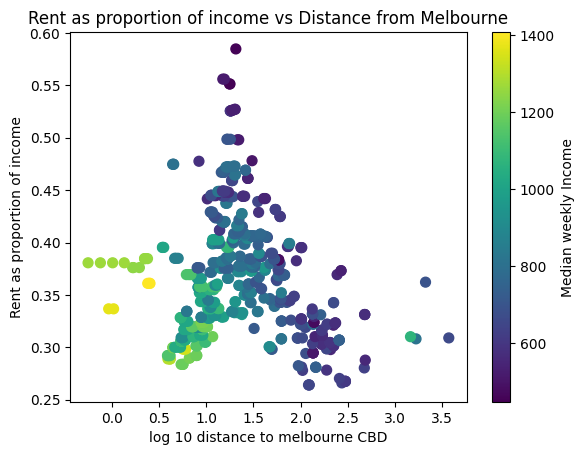

In [233]:
plt.scatter(np.log10(affordability_df['distance_to_melb_cbd_km']), affordability_df['rent as proportion of income'], c=affordability_df['median equivalised total household income (weekly) ($) 2021'], cmap='viridis', s=50)  # 'viridis' is a colormap
plt.xlabel('log 10 distance to melbourne CBD')
plt.ylabel('Rent as proportion of income')

# Add a colorbar to show the mapping
colorbar = plt.colorbar()
colorbar.set_label('Median weekly Income')

#adding a title
title = 'Rent as proportion of income vs Distance from Melbourne'
plt.title(title)

#saving the plot
path = f"../plots/{title.replace(' ', '_')}.png"
plt.savefig(path)



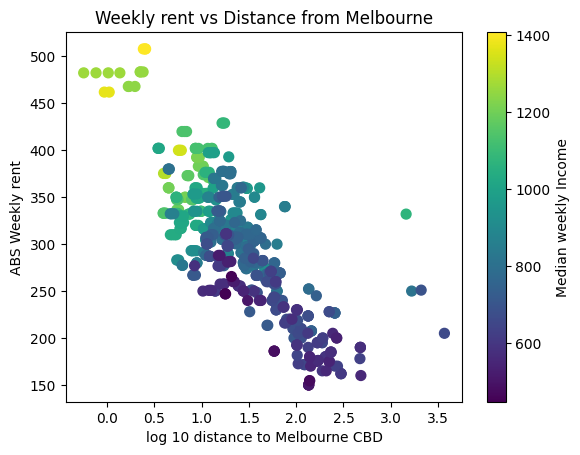

In [234]:
plt.scatter(np.log10(affordability_df['distance_to_melb_cbd_km']), affordability_df['median weekly household rental payment ($) 2021'], c=affordability_df['median equivalised total household income (weekly) ($) 2021'], cmap='viridis', s=50)  # 'viridis' is a colormap
plt.xlabel('log 10 distance to Melbourne CBD')
plt.ylabel('ABS Weekly rent')

# Add a colorbar to show the mapping
colorbar = plt.colorbar()
colorbar.set_label('Median weekly Income')

#adding a title
title = 'Weekly rent vs Distance from Melbourne'
plt.title(title)

#saving the plot
path = f"../plots/{title.replace(' ', '_')}.png"
plt.savefig(path)


# I could fit a regression and find the values with the largest  negative residuals


Text(0.5, 1.0, 'Weekly rent vs Distance from Melbourne')

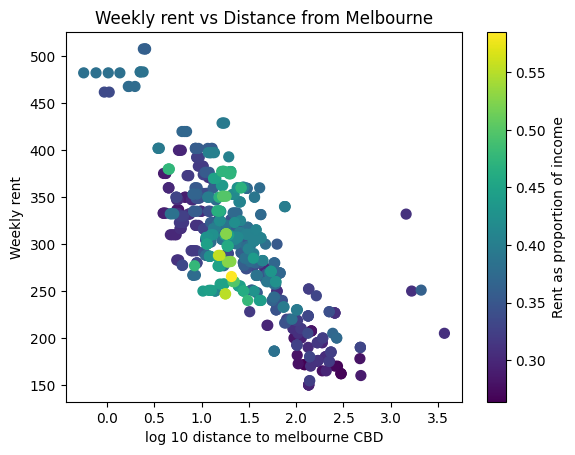

In [236]:
plt.scatter(np.log10(affordability_df['distance_to_melb_cbd_km']), affordability_df['median weekly household rental payment ($) 2021'], c=affordability_df['rent as proportion of income'], cmap='viridis', s=50)  # 'viridis' is a colormap
plt.xlabel('log 10 distance to melbourne CBD')
plt.ylabel('Weekly rent')

# Add a colorbar to show the mapping
colorbar = plt.colorbar()
colorbar.set_label('Rent as proportion of income')

#adding a title
title = 'Weekly rent vs Distance from Melbourne'
plt.title(title)

# I could fit a regression and find the values with the largest  negative residuals

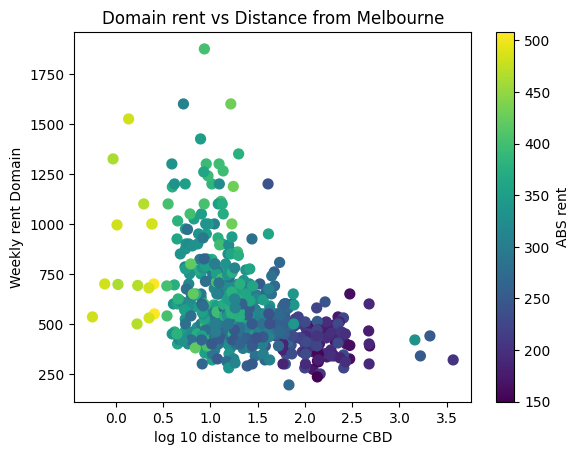

In [237]:

plt.scatter(np.log10(affordability_df['distance_to_melb_cbd_km']), affordability_df['weekly rent amount'], c=affordability_df['median weekly household rental payment ($) 2021'],  cmap='viridis', s=50)  # 'viridis' is a colormap
plt.xlabel('log 10 distance to melbourne CBD')
plt.ylabel('Weekly rent Domain')


# Add a colorbar to show the mapping
colorbar = plt.colorbar()
colorbar.set_label('ABS rent')

#adding a title
title = 'Domain rent vs Distance from Melbourne'
plt.title(title)

#saving the plot
path = f"../plots/{title.replace(' ', '_')}.png"
plt.savefig(path)


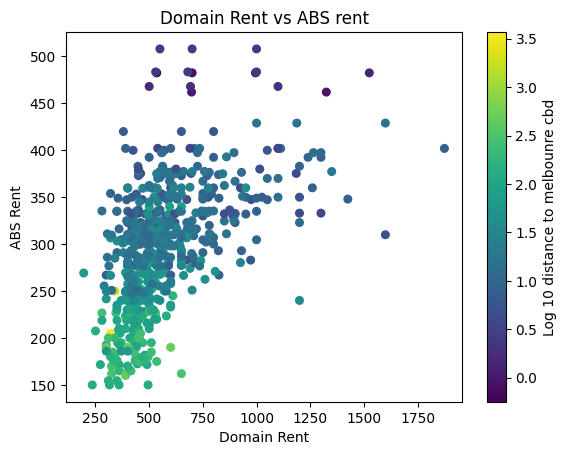

In [238]:
plt.scatter(affordability_df['weekly rent amount'], affordability_df['median weekly household rental payment ($) 2021'], c=np.log10(affordability_df['distance_to_melb_cbd_km']), cmap='viridis', s=30)  # 'viridis' is a colormap
plt.xlabel('Domain Rent')
plt.ylabel('ABS Rent')

# Add a colorbar to show the mapping
colorbar = plt.colorbar()
colorbar.set_label('Log 10 distance to melbounre cbd')

#adding a title
title = 'Domain Rent vs ABS rent'
plt.title(title)

#saving the plot
path = f"../plots/{title.replace(' ', '_')}.png"
plt.savefig(path)


Text(0, 0.5, 'distance_to_melb_cbd_km')

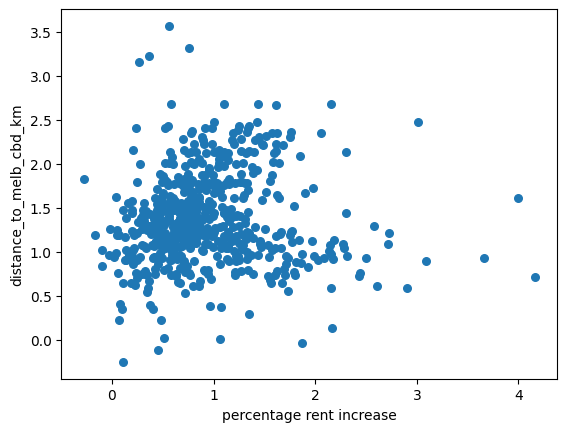

In [183]:
#Distance by percentage increase in price

affordability_df['percentage_increase_price'] = (affordability_df['weekly rent amount'] - affordability_df['median weekly household rental payment ($) 2021']) / affordability_df['median weekly household rental payment ($) 2021']
plt.scatter(affordability_df['percentage_increase_price'], np.log10(affordability_df['distance_to_melb_cbd_km']), s=30)  # 'viridis' is a colormap
plt.xlabel('percentage rent increase')
plt.ylabel('distance_to_melb_cbd_km')


In [197]:
#i need a bedroom metric


In [ ]:
#cost per family member


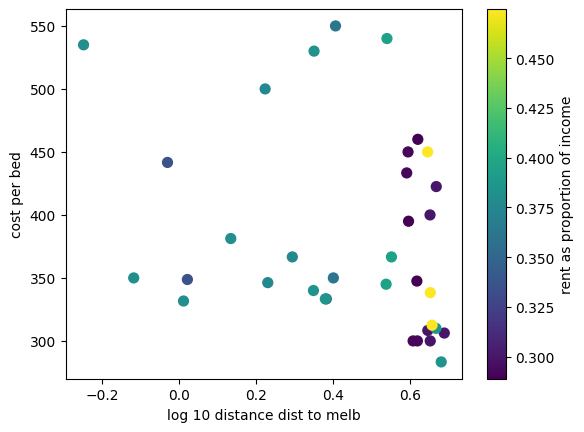

In [202]:
#cost per bedroom
affordability_df['cost per bed'] = affordability_df['weekly rent amount'] / affordability_df['beds']
plt.scatter(np.log10(affordability_5km_df['distance_to_melb_cbd_km']), affordability_5km_df['cost per bed'], c=affordability_5km_df['rent as proportion of income'], cmap='viridis', s=50)  # 'viridis' is a colormap
plt.xlabel('log 10 distance dist to melb')
plt.ylabel('cost per bed')

colorbar = plt.colorbar()
colorbar.set_label('rent as proportion of income')

#those low rent as proportion of income and around 0.75 distance ones look ideal to me. 


In [217]:
# Could do cuts of different distances, and then use a linear combination of cost per bed and proportion of income

# i could do current affordability - abs data
# and future affordability - domain data and the increase in rents based upon difference between domain and abs



# distance to public transport will be good,
affordability_5km_df.head(50)

,postcode,beds,weekly rent amount,median weekly household rental payment ($) 2021,median equivalised total household income (weekly) ($) 2021,number of properties,distance_to_melb_cbd_km,average family size (no. of persons) 2021,rent as proportion of income,percentage_increase_price,cost per bed
402,3141,2,695.0,375.333333,1299.333333,94,4.147990,2.433333,0.288866,0.851687,347.500000
401,3141,1,460.0,375.333333,1299.333333,57,4.171799,2.433333,0.288866,0.225577,460.000000
403,3141,3,1185.0,375.333333,1299.333333,21,3.946100,2.433333,0.288866,2.157194,395.000000
536,3182,1,450.0,333.000000,1140.000000,43,3.934390,2.466667,0.292105,0.351351,450.000000
537,3182,2,600.0,333.000000,1140.000000,52,4.055906,2.466667,0.292105,0.801802,300.000000
538,3182,3,1300.0,333.000000,1140.000000,18,3.903366,2.466667,0.292105,2.903904,433.333333
539,3182,4,1200.0,333.000000,1140.000000,7,4.160871,2.466667,0.292105,2.603604,300.000000
533,3181,2,600.0,360.000000,1201.000000,55,4.493775,2.450000,0.299750,0.666667,300.000000
532,3181,1,400.0,360.000000,1201.000000,33,4.487956,2.450000,0.299750,0.111111,400.000000
534,3181,3,925.0,360.000000,1201.000000,17,4.428889,2.450000,0.299750,1.569444,308.333333


In [214]:
# may want to take the average of each suburb this will be more holistic

def most_affordable(affordability_df, metrics):
    z_scores = {}

    #get the z score for each datapoint over each metric
    for metric in metrics:
        data = affordability_df[metric].values
        data_z_scores = (data - np.mean(data)) / np.std(data)
        z_scores[metric] = data_z_scores


    # Adding the z scores together
    z_score_list = list(z_scores.values())
    sum_z_scores = np.sum(z_score_list, axis=0)
    
    # Finding the postcode with the smallest cumulative z score
    min_index = np.argmin(sum_z_scores)
    postcodes = affordability_df['postcode'].values
    most_affordable_suburb = postcodes[min_index]


    return most_affordable_suburb


In [263]:
#the smallest combinations of z scores is the most liveable
affordability_range = {}

for distance in [5, 10, 25, 50, 100, 105, 200]:
    aff_df = affordability_df[affordability_df['distance_to_melb_cbd_km'] <= distance]
    affordable_suburb = most_affordable(aff_df, ['cost per bed', 'rent as proportion of income'])
    affordability_range[distance] = affordable_suburb

most_affordable_suburbs = pd.DataFrame(list(affordability_range.items()), columns=['Radius from Melbourne (km)', 'Most Affordable Suburb'])
# still need to average the scores by suburb
most_affordable_suburbs.to_csv('../data/curated/most_affordable_suburbs.csv', index=False)
